Spectrum of Cesium-137

In [54]:
import matplotlib.pyplot as plt
import numpy as np 

In [55]:
with open("spectrum_cs137.csv", "r") as file:
    pulseheight = []
    counts = []
    i = 0

    for line in file:
        data = line.split(',')

        if i > 0:
            pulseheight.append(float(data[0]))
            counts.append(float(data[1]))
        else:
            i+=1


In [ ]:
# Voorbereiden voor fit
pulseheight_peak=[]
for a in pulseheight:
    if a in range (0,len(pulseheight)):
        pulseheight_peak.append(pulseheight[a])
        



In [59]:
# import numpy as np
# Fit_counts = []
# for i in pulseheight_peak:
#     def gauss(x, A, x0, sigma):
#         return A * np.exp(-(x - x0)**2 / (2 * sigma**2))
#     Fit_count = gauss(i, 625, 2000, 100)
#     Fit_counts.append(Fit_count)
#     i+=1

import lmfit
import numpy as np


# 1. Definieer de Gauss-functie (buiten de for-loop)
def gauss(x, A, x0, sigma):
    return A * np.exp(-((x - x0) ** 2) / (2 * sigma**2))


# 2. Maak een lmfit Model aan van de functie
model = lmfit.Model(gauss)

# 3. Stel de beginwaarden (initial guesses) in voor de parameters
params = model.make_params(A=625, x0=2000, sigma=100)

# 4. Voer de fit uit op de gemeten data
# x_data: je pulseheight_peak array
# y_data: de gemeten counts die bij deze pulseheights horen
result = model.fit(pulseheight_peak, params, x=counts)

# 5. Print het complete fit-rapport
print(result.fit_report())

ValueError: operands could not be broadcast together with shapes (328,) (499,) 

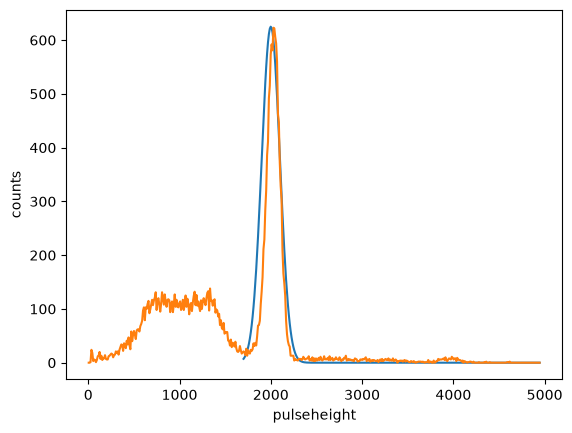

In [58]:
plt.plot(pulseheight_peak,Fit_counts)
plt.plot(pulseheight, counts)
plt.xlabel("pulseheight")
plt.ylabel("counts")
plt.show()